# Convolution Filters, Data Imbalance and Vanishing Gradients in Python, Line by Line

**Neural Network Lab · CSIT843A Lecture 6** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/NeuralNetwork/code-problems.html**

A complete, runnable notebook for Parts 3 and 4. Slide filters over a digit and pool the feature maps, reproduce the fraud experiment (accuracy against recall, class weights, SMOTE, undersampling), measure vanishing gradients layer by layer and see why clipping stops exploding gradients. NumPy, Matplotlib and scikit-learn. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Write a 2-D convolution and max-pooling by hand
2. Show that accuracy hides a rare class
3. Use class weights, SMOTE and undersampling, and tune the threshold
4. Measure the gradient in every layer of a deep network
5. Explain exploding gradients and gradient clipping

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Setup

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"

import gzip, os, urllib.request

URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"

def load(name, offset):
    if not os.path.exists(name):
        urllib.request.urlretrieve(URL + name, name)
    with gzip.open(name) as f:
        return np.frombuffer(f.read(), np.uint8, offset=offset)

X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_train = load("train-labels-idx1-ubyte.gz", 8)
X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_test = load("t10k-labels-idx1-ubyte.gz", 8)
print(X_test.shape)

(10000, 784)


**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   Sharper plots in Jupyter.
2. `import numpy as np`  
   Arrays and maths.
3. `import matplotlib.pyplot as plt`  
   Charts.
4. `from sklearn.linear_model import LogisticRegression`  
   A single sigmoid neuron, trained for us.
5. `from sklearn.metrics import accuracy_score, recall_score, precision_score`  
   The three measures of Part 4.
6. `plt.rcParams["figure.figsize"] = (7, 4)`  
   Default figure size (width, height) in inches.
7. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
8. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.
9. `import gzip, os, urllib.request`  
   Standard-library tools to download and unzip the data files.
10. `URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"`  
   A public copy of the MNIST files on GitHub.
11. `def load(name, offset):`  
   Download one MNIST file (once) and read it as bytes.
12. `if not os.path.exists(name):` …  
   Only download if we do not have the file yet.
13. `with gzip.open(name) as f:`  
   The files are gzip-compressed.
14. `return np.frombuffer(f.read(), np.uint8, offset=offset)`  
   Skip the header (16 bytes for images, 8 for labels) and read the rest as numbers 0–255.
15. `X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255`  
   60,000 training pictures, each a row of 784 pixels, scaled to 0 … 1.
16. `y_train = load("train-labels-idx1-ubyte.gz", 8)`  
   Their labels: the digit 0–9 each picture shows.
17. `X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255` …  
   10,000 test pictures the network never trains on.
18. `print(X_test.shape)`  
   We only need a few test digits here.

## 2. Convolution by hand

A 3 × 3 filter slides over the 28 × 28 picture. At each position: multiply the 9 filter weights by the 9 pixels under them and add up: $y_{i,j} = \sum_u \sum_v k_{u,v}\, x_{i+u,\,j+v}$.

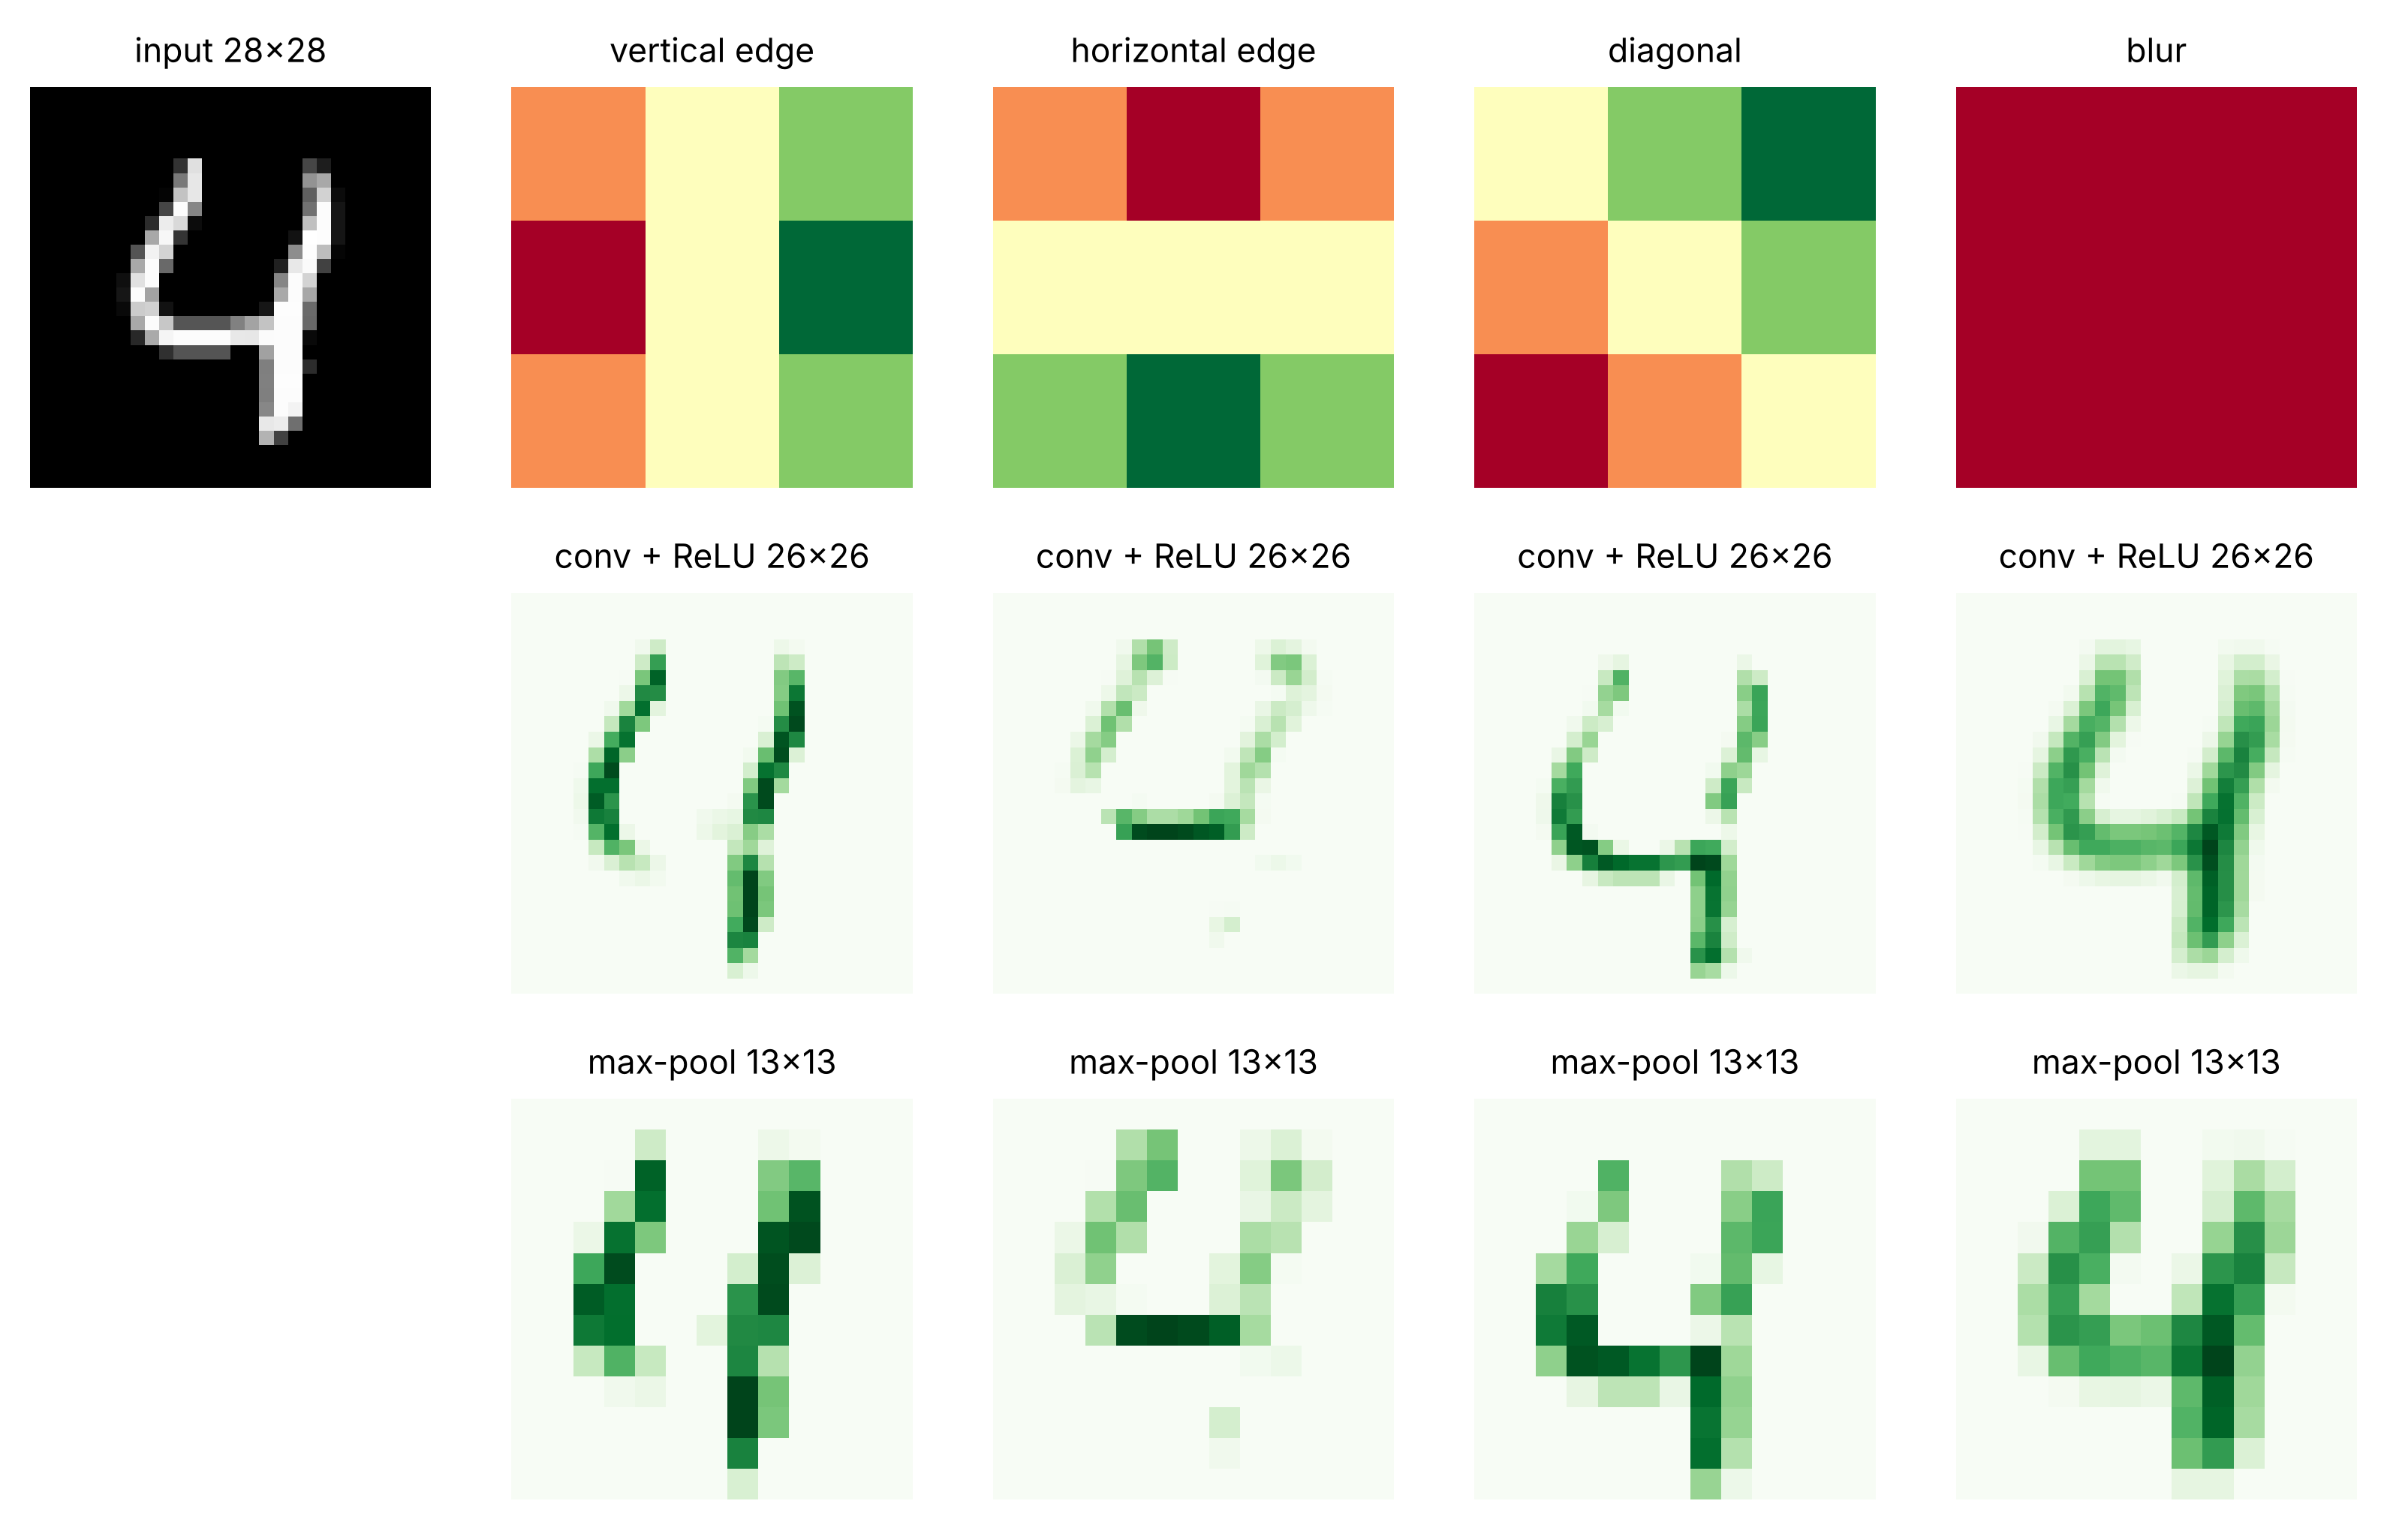

weights in one 3×3 filter: 9   ·   weights from 784 pixels to 16 dense neurons: 12544


In [2]:
def conv2d(img, k):
    H, W = img.shape[0] - 2, img.shape[1] - 2
    out = np.zeros((H, W))
    for i in range(H):
        for j in range(W):
            out[i, j] = (img[i:i + 3, j:j + 3] * k).sum()
    return out

def maxpool(fm):
    h, w = fm.shape[0] // 2, fm.shape[1] // 2
    return fm[:2 * h, :2 * w].reshape(h, 2, w, 2).max(axis=(1, 3))

filters = {
    "vertical edge": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "diagonal": np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]]),
    "blur": np.ones((3, 3)) / 9,
}

img = X_test[4].reshape(28, 28)
fig, axes = plt.subplots(3, 5, figsize=(10, 6.2))
axes[0, 0].imshow(img, cmap="gray"); axes[0, 0].set_title("input 28×28", fontsize=8)
for c, (name, k) in enumerate(filters.items(), start=1):
    fm = np.maximum(0, conv2d(img, k))
    axes[0, c].imshow(k, cmap="RdYlGn"); axes[0, c].set_title(name, fontsize=8)
    axes[1, c].imshow(fm, cmap="Greens"); axes[1, c].set_title("conv + ReLU 26×26", fontsize=8)
    axes[2, c].imshow(maxpool(fm), cmap="Greens"); axes[2, c].set_title("max-pool 13×13", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.show()
print("weights in one 3×3 filter: 9   ·   weights from 784 pixels to 16 dense neurons:", 784 * 16)

**Line by line**

1. `def conv2d(img, k):`  
   “Valid” convolution: the filter stays inside the picture, so 28 → 26.
2. `H, W = img.shape[0] - 2, img.shape[1] - 2` …  
   Output size.
3. `for i in range(H):`  
   Every row position …
4. `for j in range(W):`  
   … and every column position.
5. `out[i, j] = (img[i:i + 3, j:j + 3] * k).sum()` …  
   The 3 × 3 patch times the filter, added up.
6. `def maxpool(fm):` …  
   2 × 2 max-pooling: keep the largest value of each block, 26 → 13.
7. `return fm[:2 * h, :2 * w].reshape(h, 2, w, 2).max(axis=(1, 3))`  
   Group pixels into 2 × 2 blocks and take each block’s maximum.
8. `filters = {`  
   Four classic filters, written by hand (a CNN learns its own).
9. `"vertical edge": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),`  
   Responds where brightness changes from left to right.
10. `"horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),`  
   … from top to bottom.
11. `"diagonal": np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]]),`  
   … along a diagonal.
12. `"blur": np.ones((3, 3)) / 9,` …  
   The average of the 9 pixels: smooths the picture.
13. `img = X_test[4].reshape(28, 28)`  
   One test digit (a 4).
14. `fig, axes = plt.subplots(3, 5, figsize=(10, 6.2))` …  
   Rows: input, feature map, pooled map.
15. `for c, (name, k) in enumerate(filters.items(), start=1):`  
   One column per filter.
16. `fm = np.maximum(0, conv2d(img, k))`  
   Convolution followed by ReLU.
17. `axes[0, c].imshow(k, cmap="RdYlGn"); axes[0, c].set_title(name, fontsize=8)`  
   The filter itself.
18. `axes[1, c].imshow(fm, cmap="Greens"); axes[1, c].set_title("conv + ReLU 26×26", fontsize=8)`  
   Bright where the pattern is found.
19. `axes[2, c].imshow(maxpool(fm), cmap="Greens"); axes[2, c].set_title("max-pool 13×13", fontsize=8)` …  
   Smaller, keeps the strongest responses.
20. `print("weights in one 3×3 filter: 9   ·   weights from 784 pixels to 16 dense neurons:", 784 * 16)`  
   Why CNNs need far fewer weights.

## 3. Data imbalance: 10,000 payments, 2% fraud

Simulate two features per payment (think: scaled amount and time of night). Frauds are shifted, but overlap with normal payments. 3,000 payments are held out for testing.

In [3]:
rng = np.random.default_rng(2024)
n = 10_000
y = (np.arange(n) % 50 == 0).astype(int)
X = rng.normal(size=(n, 2))
X[y == 1] = rng.normal(size=(y.sum(), 2)) * 0.95 + [1.5, 1.2]
perm = rng.permutation(n); X, y = X[perm], y[perm]
Xtr, ytr, Xte, yte = X[:7000], y[:7000], X[7000:], y[7000:]
print("frauds in training set:", ytr.sum(), "  in test set:", yte.sum())

frauds in training set: 140   in test set: 60


**Line by line**

1. `rng = np.random.default_rng(2024)`  
   Fixed seed: same data every run.
2. `n = 10_000`  
   Payments.
3. `y = (np.arange(n) % 50 == 0).astype(int)`  
   Every 50th payment is fraud: 2%.
4. `X = rng.normal(size=(n, 2))`  
   Legitimate payments: centred at (0, 0).
5. `X[y == 1] = rng.normal(size=(y.sum(), 2)) * 0.95 + [1.5, 1.2]`  
   Frauds: shifted, but overlapping.
6. `perm = rng.permutation(n); X, y = X[perm], y[perm]`  
   Shuffle.
7. `Xtr, ytr, Xte, yte = X[:7000], y[:7000], X[7000:], y[7000:]`  
   7,000 to train, 3,000 to test.
8. `print("frauds in training set:", ytr.sum(), "  in test set:", yte.sum())`  
   About 140 and 60.

In [4]:
def smote(X, y, k=3, seed=0):
    r = np.random.default_rng(seed)
    F = X[y == 1]
    need = (y == 0).sum() - len(F)
    d = ((F[:, None, :] - F[None, :, :]) ** 2).sum(-1)
    nb = np.argsort(d, axis=1)[:, 1:k + 1]
    a = r.integers(len(F), size=need)
    b = nb[a, r.integers(k, size=need)]
    t = r.random((need, 1))
    new = F[a] + t * (F[b] - F[a])
    return np.vstack([X, new]), np.concatenate([y, np.ones(need, int)])

def undersample(X, y, ratio=4, seed=0):
    r = np.random.default_rng(seed)
    keep = np.concatenate([np.where(y == 1)[0], r.choice(np.where(y == 0)[0], ratio * y.sum(), replace=False)])
    return X[keep], y[keep]

def report(name, model):
    p = model.predict(Xte)
    print(f"{name:30s} accuracy {accuracy_score(yte, p):6.1%}   recall {recall_score(yte, p):4.0%}   "
          f"precision {precision_score(yte, p, zero_division=0):4.0%}   caught {int(((p == 1) & (yte == 1)).sum())} of {yte.sum()}")

print(f"{'always legitimate':30s} accuracy {(yte == 0).mean():6.1%}   recall   0%")
report("trained on the data as it is", LogisticRegression().fit(Xtr, ytr))
report("+ class weights", LogisticRegression(class_weight="balanced").fit(Xtr, ytr))
report("+ SMOTE (training set only)", LogisticRegression().fit(*smote(Xtr, ytr)))
report("+ undersampling 4:1", LogisticRegression().fit(*undersample(Xtr, ytr)))

always legitimate              accuracy  98.0%   recall   0%
trained on the data as it is   accuracy  98.3%   recall  18%   precision  85%   caught 11 of 60
+ class weights                accuracy  84.8%   recall  83%   precision  10%   caught 50 of 60
+ SMOTE (training set only)    accuracy  85.0%   recall  83%   precision  10%   caught 50 of 60
+ undersampling 4:1            accuracy  95.2%   recall  62%   precision  23%   caught 37 of 60


**Line by line**

1. `def smote(X, y, k=3, seed=0):` …  
   SMOTE (Chawla et al., 2002), written out.
2. `F = X[y == 1]`  
   The minority (fraud) points.
3. `need = (y == 0).sum() - len(F)`  
   How many synthetic points to reach 50 : 50.
4. `d = ((F[:, None, :] - F[None, :, :]) ** 2).sum(-1)`  
   Squared distance between every pair of frauds.
5. `nb = np.argsort(d, axis=1)[:, 1:k + 1]`  
   The k nearest fraud neighbours of each fraud (column 0 is itself).
6. `a = r.integers(len(F), size=need)`  
   Pick a random fraud …
7. `b = nb[a, r.integers(k, size=need)]`  
   … and one of its neighbours.
8. `t = r.random((need, 1))`  
   A random position between them.
9. `new = F[a] + t * (F[b] - F[a])`  
   The synthetic frauds.
10. `return np.vstack([X, new]), np.concatenate([y, np.ones(need, int)])`  
   Original data plus the new points.
11. `def undersample(X, y, ratio=4, seed=0):` …  
   Keep all frauds and only 4 legitimate payments per fraud.
12. `def report(name, model):`  
   One line of the results table, on the untouched test set.
13. `p = model.predict(Xte)` …  
   Threshold 0.5.
14. `print(f"{'always legitimate':30s} accuracy {(yte == 0).mean():6.1%}   recall   0%")`  
   The lazy model: high accuracy, catches nothing.
15. `report("trained on the data as it is", LogisticRegression().fit(Xtr, ytr))`  
   Accuracy about 98%, recall tiny.
16. `report("+ class weights", LogisticRegression(class_weight="balanced").fit(Xtr, ytr))`  
   A missed fraud now costs about 49× more.
17. `report("+ SMOTE (training set only)", LogisticRegression().fit(*smote(Xtr, ytr)))`  
   Synthetic frauds in the training set only.
18. `report("+ undersampling 4:1", LogisticRegression().fit(*undersample(Xtr, ytr)))`  
   Fewer legitimate payments.

### Moving the threshold

The plain model outputs a probability. Lowering the threshold from 0.5 catches more fraud but raises more false alarms.

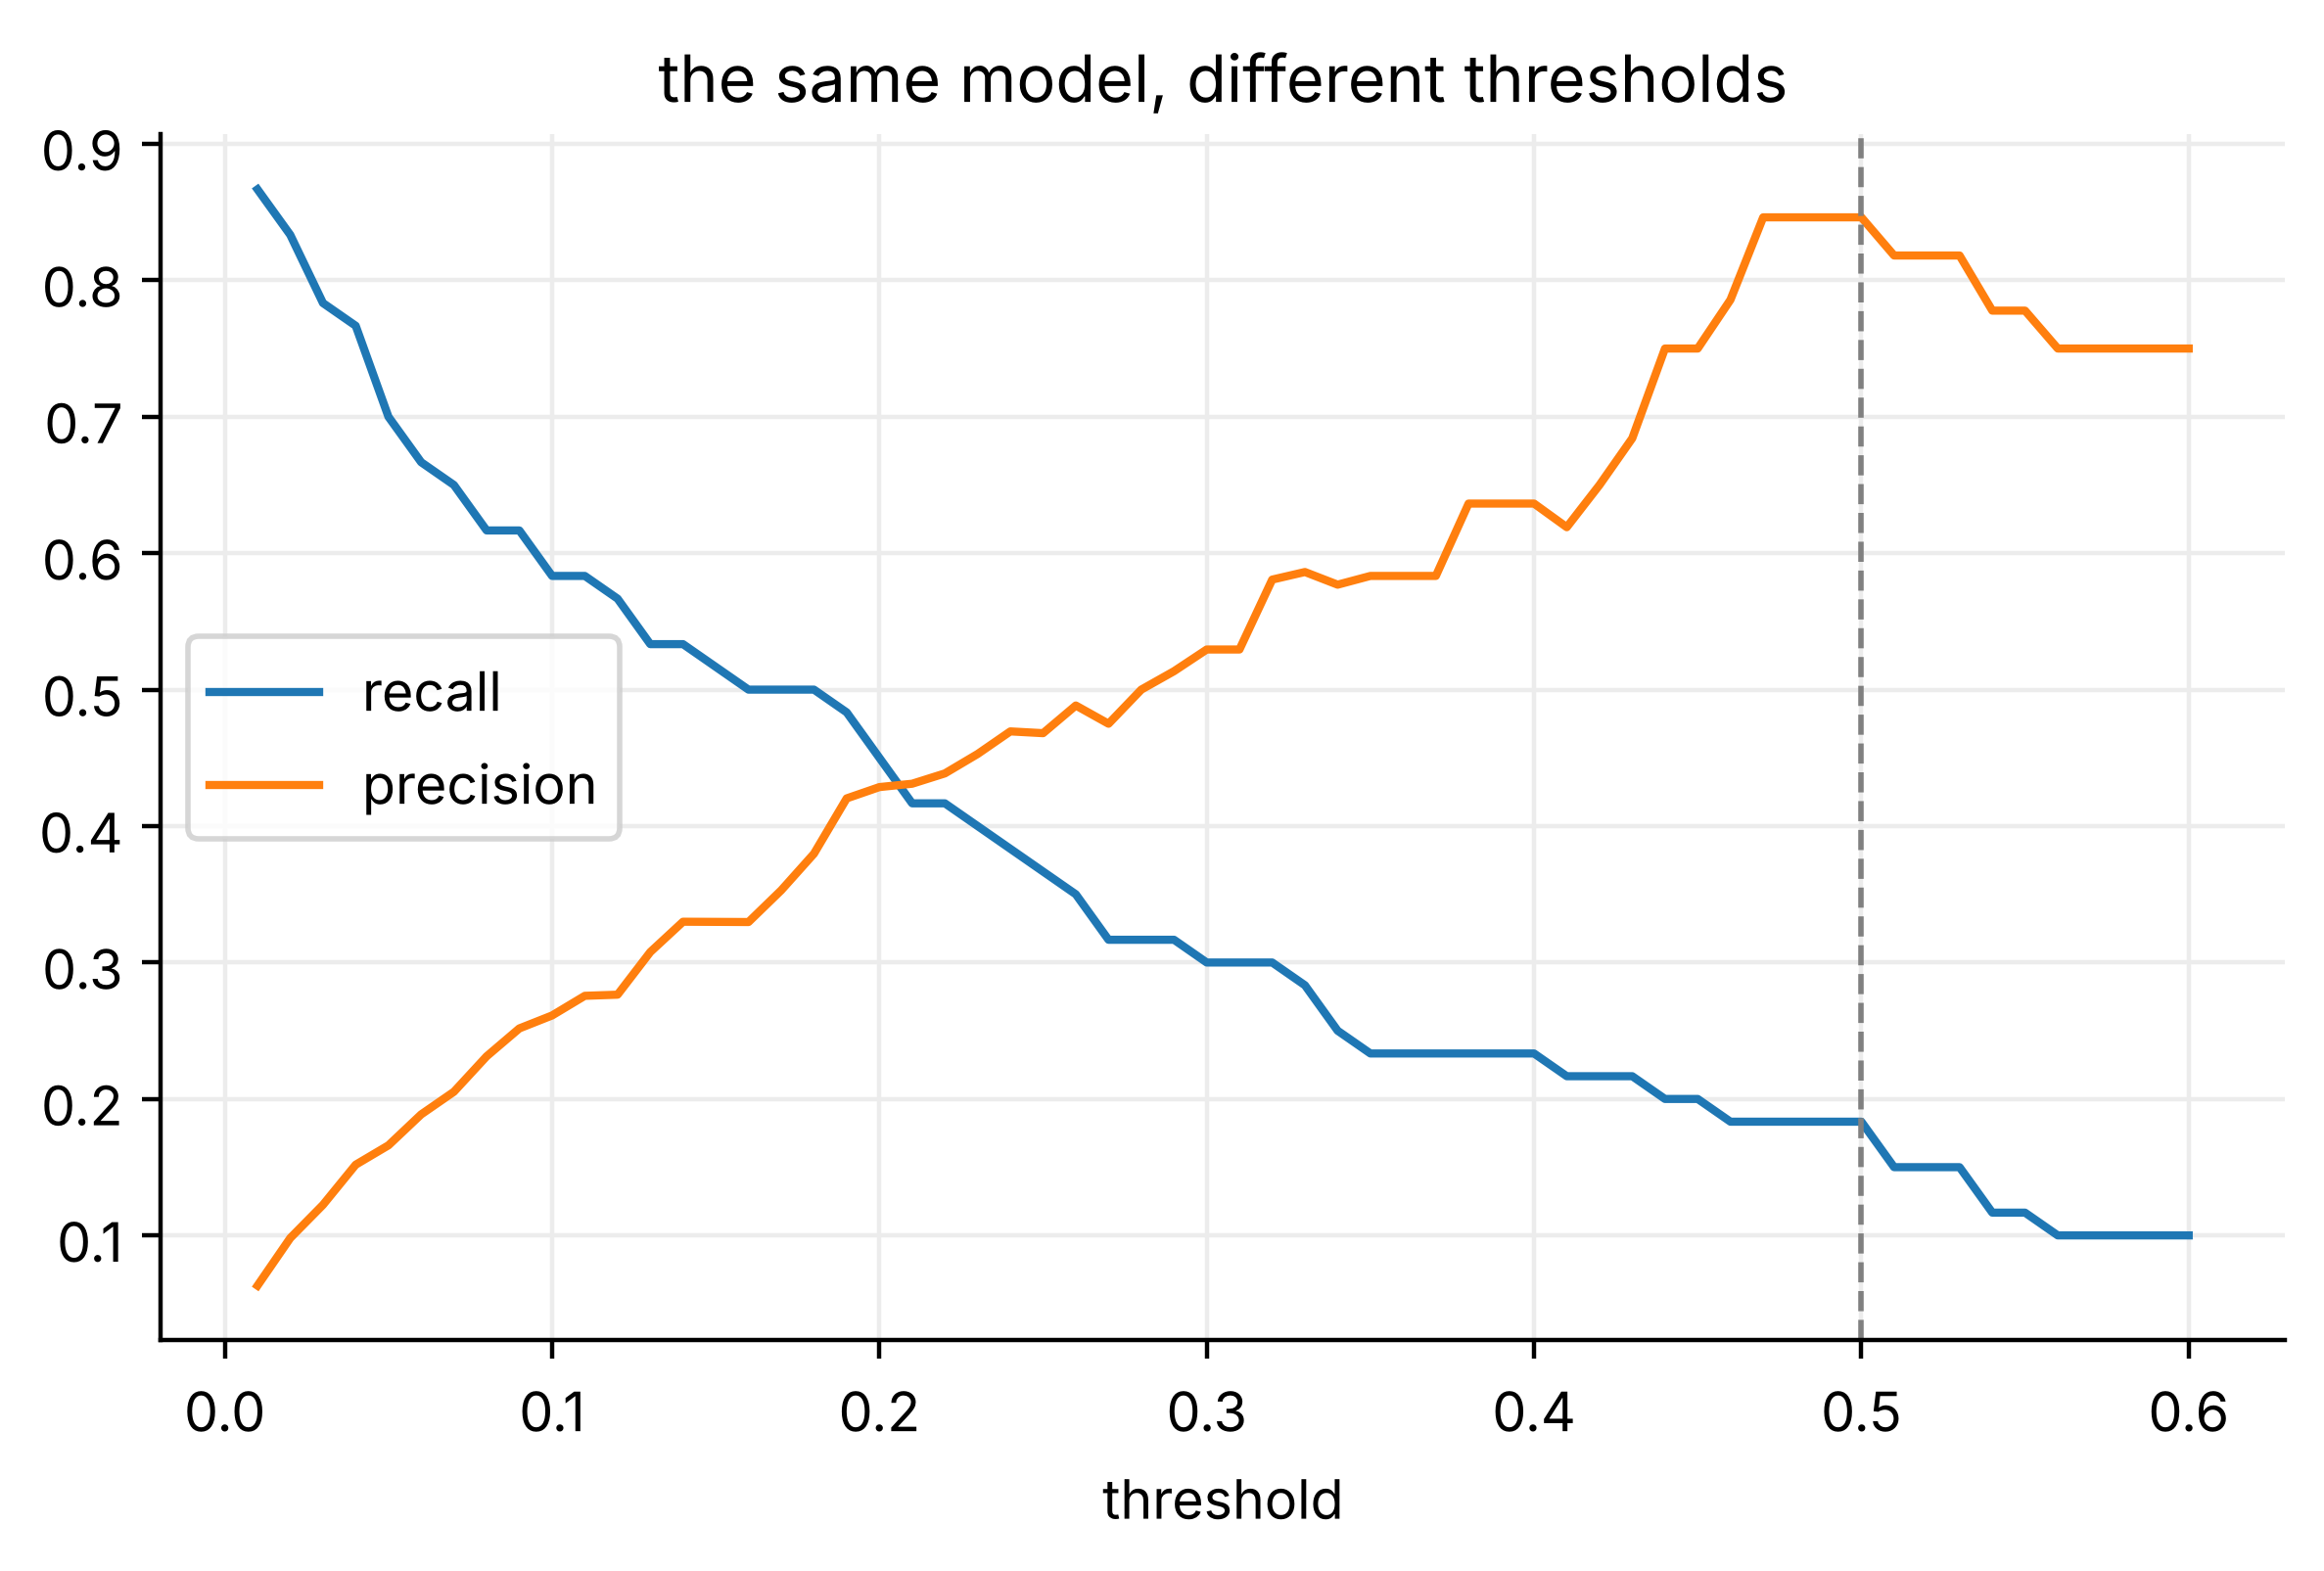

In [5]:
plain = LogisticRegression().fit(Xtr, ytr)
prob = plain.predict_proba(Xte)[:, 1]
ts = np.linspace(0.01, 0.6, 60)
rec = [recall_score(yte, prob >= t) for t in ts]
pre = [precision_score(yte, prob >= t, zero_division=0) for t in ts]
plt.plot(ts, rec, label="recall"); plt.plot(ts, pre, label="precision")
plt.axvline(0.5, color="gray", ls="--", lw=1)
plt.xlabel("threshold"); plt.legend(); plt.title("the same model, different thresholds")
plt.show()

**Line by line**

1. `plain = LogisticRegression().fit(Xtr, ytr)`  
   The model trained on the data as it is.
2. `prob = plain.predict_proba(Xte)[:, 1]`  
   Its fraud probability for each test payment.
3. `ts = np.linspace(0.01, 0.6, 60)`  
   Thresholds to try.
4. `rec = [recall_score(yte, prob >= t) for t in ts]`  
   Recall at each threshold.
5. `pre = [precision_score(yte, prob >= t, zero_division=0) for t in ts]` …  
   Precision at each threshold.
6. `plt.axvline(0.5, color="gray", ls="--", lw=1)` …  
   The default threshold.
7. `plt.show()`  
   Where to stand is a business decision: missed fraud against annoyed customers.

## 4. Vanishing gradients, measured

A 10-layer network of 32 neurons per layer. Push 64 random inputs through, backpropagate a cost, and record the average size of the weight gradients in each layer.

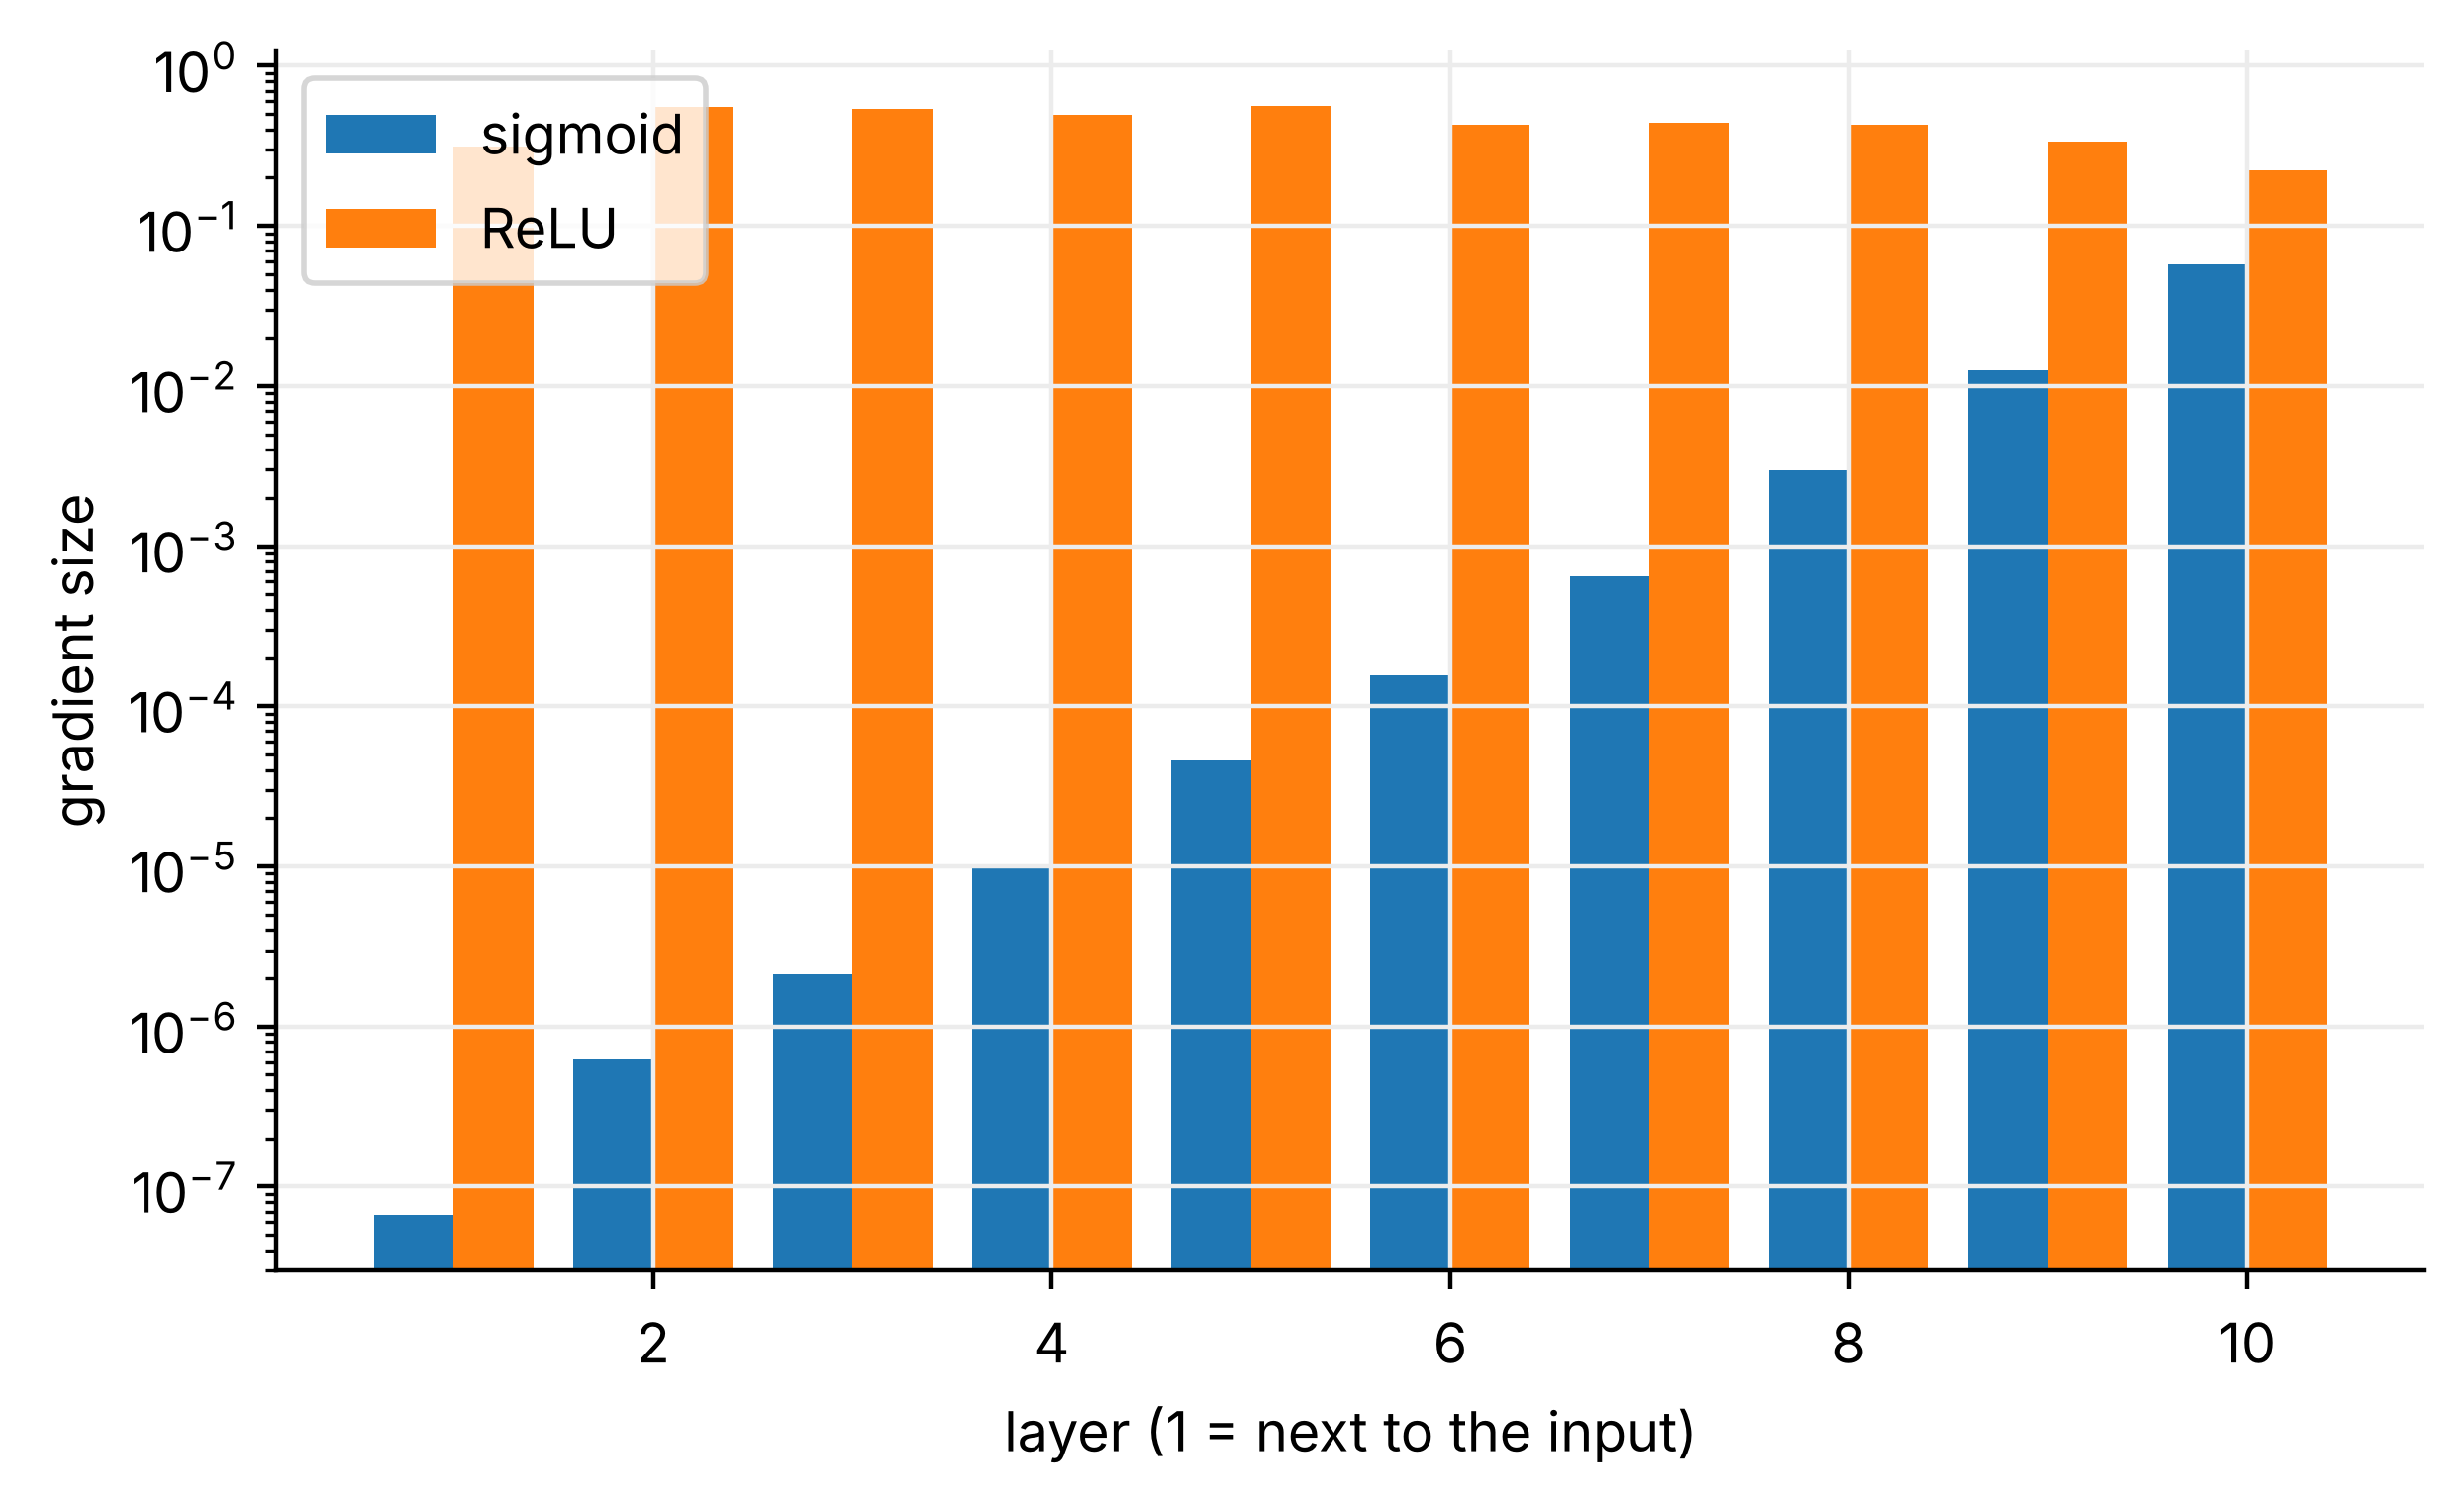

sigmoid: last layer / first layer = 874,025×


In [6]:
def grad_sizes(act, depth=10, width=32, seed=3):
    r = np.random.default_rng(seed)
    f, df = {"sigmoid": (lambda z: 1 / (1 + np.exp(-z)), lambda a: a * (1 - a)),
             "relu": (lambda z: np.maximum(0, z), lambda a: (a > 0).astype(float))}[act]
    scale = np.sqrt(2 / width) if act == "relu" else 1 / np.sqrt(width)
    W = [r.normal(0, scale, (width, width)) for _ in range(depth)]
    acts = [r.normal(size=(64, width))]
    for Wl in W: acts.append(f(acts[-1] @ Wl.T))
    delta = (acts[-1] - r.normal(size=acts[-1].shape)) * df(acts[-1])
    sizes = []
    for l in range(depth - 1, -1, -1):
        sizes.append(np.abs(delta.T @ acts[l]).mean() / 64)
        delta = (delta @ W[l]) * df(acts[l])
    return sizes[::-1]

layers = np.arange(1, 11)
plt.bar(layers - 0.2, grad_sizes("sigmoid"), 0.4, label="sigmoid")
plt.bar(layers + 0.2, grad_sizes("relu"), 0.4, label="ReLU")
plt.yscale("log"); plt.xlabel("layer (1 = next to the input)"); plt.ylabel("gradient size"); plt.legend()
plt.show()
s = grad_sizes("sigmoid"); print(f"sigmoid: last layer / first layer = {s[-1] / s[0]:,.0f}×")

**Line by line**

1. `def grad_sizes(act, depth=10, width=32, seed=3):` …  
   Average |∂C/∂w| in every layer.
2. `f, df = {"sigmoid": (lambda z: 1 / (1 + np.exp(-z)), lambda a: a * (1 - a)),` …  
   The activation and its slope (written with a = f(z)).
3. `scale = np.sqrt(2 / width) if act == "relu" else 1 / np.sqrt(width)` …  
   He initialisation for ReLU, Xavier for sigmoid.
4. `acts = [r.normal(size=(64, width))]`  
   64 random inputs.
5. `for Wl in W: acts.append(f(acts[-1] @ Wl.T))`  
   Forward pass, keeping every activation.
6. `delta = (acts[-1] - r.normal(size=acts[-1].shape)) * df(acts[-1])` …  
   Output error towards random targets.
7. `for l in range(depth - 1, -1, -1):`  
   Backpropagate.
8. `sizes.append(np.abs(delta.T @ acts[l]).mean() / 64)`  
   Size of this layer’s weight gradient.
9. `delta = (delta @ W[l]) * df(acts[l])`  
   Pass back, times the slope of the layer below.
10. `return sizes[::-1]` …  
   Layer 1 first.
11. `plt.bar(layers - 0.2, grad_sizes("sigmoid"), 0.4, label="sigmoid")`  
   Shrinks layer after layer.
12. `plt.bar(layers + 0.2, grad_sizes("relu"), 0.4, label="ReLU")`  
   Stays about the same size.
13. `plt.yscale("log"); plt.xlabel("layer (1 = next to the input)"); plt.ylabel("gradient size"); plt.legend()` …  
   Log scale: each step is 10×.
14. `s = grad_sizes("sigmoid"); print(f"sigmoid: last layer / first layer = {s[-1] / s[0]:,.0f}×")`  
   The first layers barely learn.

## 5. Exploding gradients and clipping

In an RNN the same factor is multiplied once per time step. A factor of 1.1 over 100 steps is about 14,000. Gradient clipping caps the gradient’s length: $\text{if } \lVert g \rVert > c:\ g \leftarrow c\,g/\lVert g \rVert$.

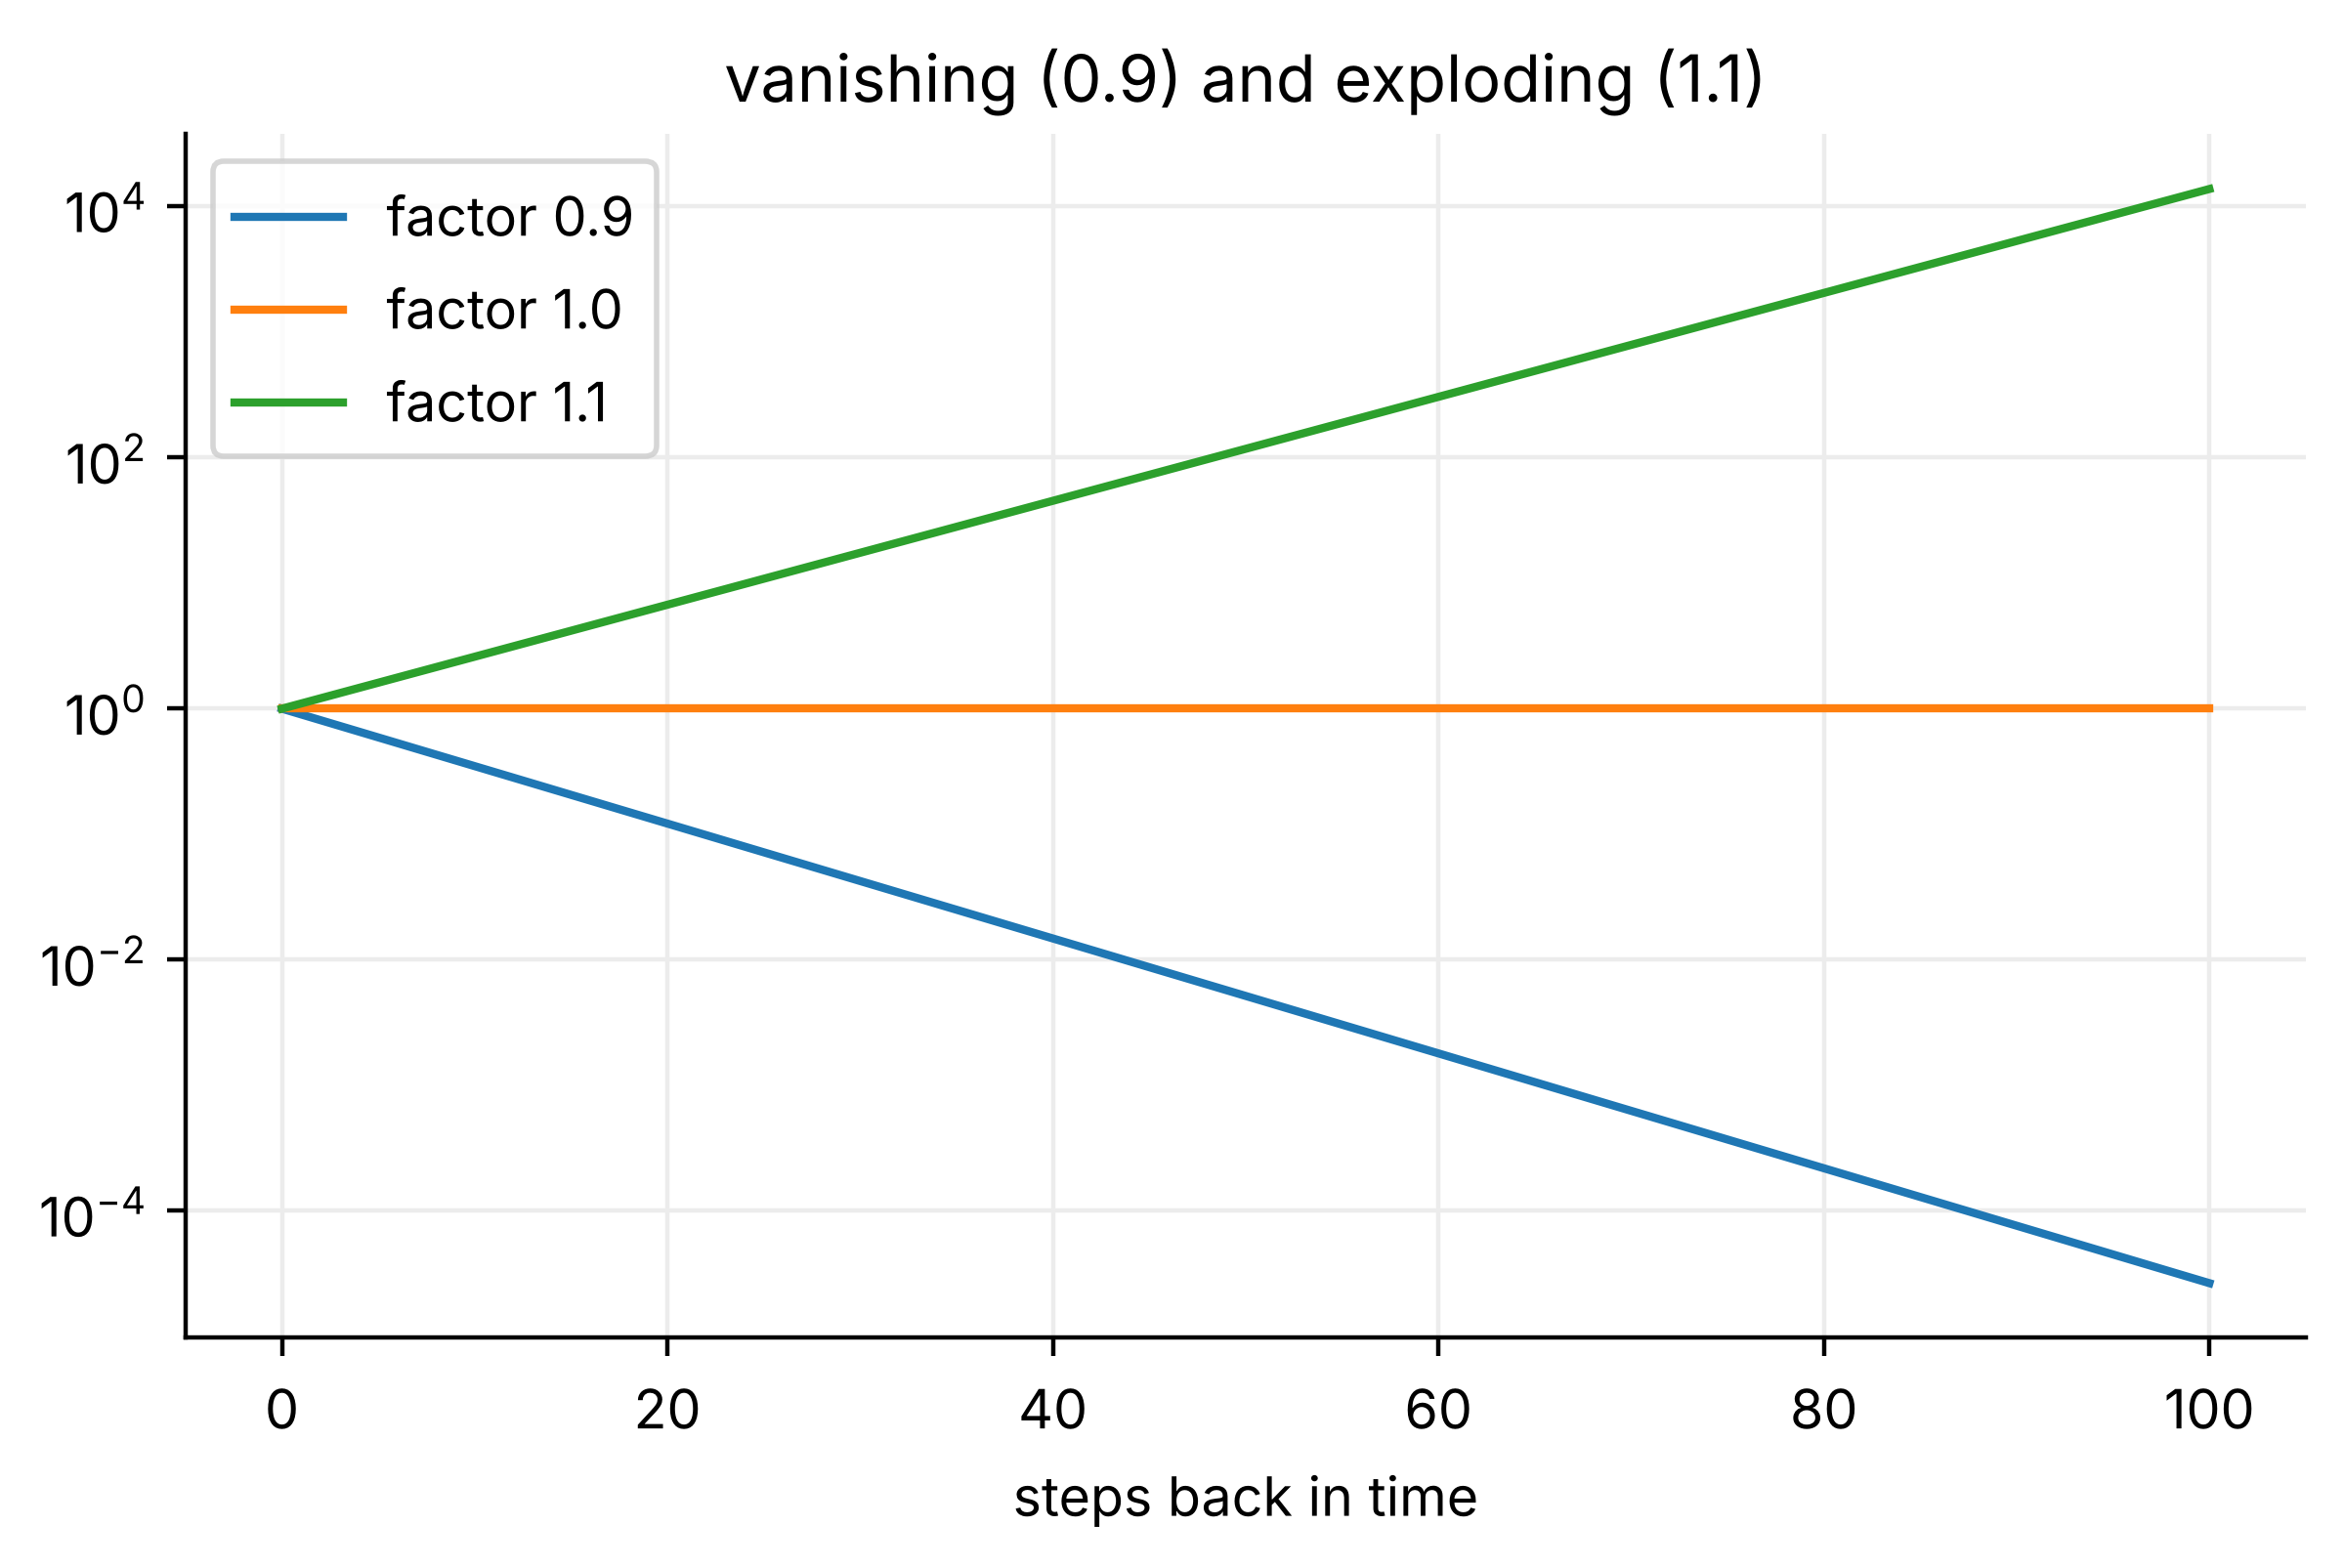

before: [ 300. -400.]  length 500.0
after:  [ 0.6 -0.8]  length 1.0


In [7]:
steps = np.arange(101)
for f in [0.9, 1.0, 1.1]:
    plt.plot(steps, f ** steps, label=f"factor {f}")
plt.yscale("log"); plt.xlabel("steps back in time"); plt.legend(); plt.title("vanishing (0.9) and exploding (1.1)")
plt.show()

def clip(g, c=1.0):
    norm = np.linalg.norm(g)
    return g * (c / norm) if norm > c else g

g = np.array([300.0, -400.0])
print("before:", g, " length", np.linalg.norm(g))
print("after: ", clip(g), " length", np.linalg.norm(clip(g)))

**Line by line**

1. `steps = np.arange(101)`  
   0 … 100 time steps.
2. `for f in [0.9, 1.0, 1.1]:`  
   Three factors per step.
3. `plt.plot(steps, f ** steps, label=f"factor {f}")` …  
   The product after t steps.
4. `def clip(g, c=1.0):`  
   Gradient clipping by length (norm).
5. `norm = np.linalg.norm(g)`  
   The length of the gradient vector.
6. `return g * (c / norm) if norm > c else g`  
   Too long: shrink to length c, same direction.
7. `g = np.array([300.0, -400.0])` …  
   An exploding gradient of length 500.
8. `print("after: ", clip(g), " length", np.linalg.norm(clip(g)))`  
   Length 1, direction unchanged.

## 6. What you built

| Problem | Symptom | Fix |
|---|---|---|
| data imbalance | high accuracy, low recall | class weights, SMOTE, threshold |
| vanishing gradient | first layers do not learn | ReLU, good initialisation, residual connections |
| exploding gradient | loss jumps or becomes NaN | gradient clipping, smaller η |

Symptom → cause → fix: say all three.